# ETF selection with a classification model

I wanted to see whether a model could help me select ETFs, and how that selection would compare with dividing the capital equally across all of them. I looked at returns, drawdowns, and the cost of changing positions.

I used methods from Analytics in Stock Markets Zoomcamp: data preparation, derived features, Decision Tree, Random Forest, chronological splits, and trading simulation. I adapted the asset universe and prediction horizon for this project.

This is a historical experiment. The final signals refer to the end of 2025, not to current trades.

## 1. Setup

The first cell installs the libraries if needed in Colab. They were already available in the recorded execution, so installation was skipped. If you use the project folder locally, install the versions in `requirements.txt`.

In [ ]:
%pip -q install yfinance pandas numpy matplotlib scikit-learn

## 2. Project functions

This cell writes `etf_project.py`. The file contains the functions for downloading data, preparing features, training, simulation, and evaluation. Keeping them in a script makes it possible to run the same analysis with one command, as in the automation module.

The imports are repeated inside the script because it must also work outside this notebook. This cell writes the file; it does not run the analysis yet.

In [1]:
%%writefile etf_project.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score
from pathlib import Path

TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM", "TLT", "IEF", "GLD"]


def download_prices(end="2026-01-01"):
    raw = yf.download(
        TICKERS,
        start="2010-01-01",
        end=end,
        auto_adjust=True,
        progress=False
    )

    if raw.empty:
        raise ValueError("No data were downloaded.")

    prices = raw["Close"].reindex(columns=TICKERS).sort_index()

    if prices.isna().any().any():
        raise ValueError("Missing prices found. Check the download.")

    if prices.index.duplicated().any():
        raise ValueError("Duplicate dates found.")

    if not np.isfinite(prices.to_numpy()).all() or (prices <= 0).any().any():
        raise ValueError("Invalid prices found.")

    return prices


def prepare_data(prices):
    frames = []

    for ticker in TICKERS:
        p = prices[ticker]
        daily_return = p / p.shift(1) - 1

        df = pd.DataFrame(index=prices.index)
        df["Ticker"] = ticker

        # Information available at the close of each session.
        for window in [1, 5, 20, 60]:
            df[f"return_{window}"] = p / p.shift(window) - 1

        df["volatility_20"] = daily_return.rolling(20).std()
        df["relative_sma_10"] = p / p.rolling(10).mean() - 1
        df["relative_sma_20"] = p / p.rolling(20).mean() - 1
        df["relative_sma_60"] = p / p.rolling(60).mean() - 1

        df["Month"] = prices.index.month.astype(str)
        df["Weekday"] = prices.index.dayofweek.astype(str)

        # Signal at the close of t.
        # Buy at the close of t+1 and sell at the close of t+2.
        df["future_return"] = p.shift(-2) / p.shift(-1) - 1

        # Date when the outcome of the trade becomes known.
        df["label_end"] = pd.Series(
            prices.index, index=prices.index
        ).shift(-2)

        frames.append(df.rename_axis("Date").reset_index())

    data = pd.concat(frames, ignore_index=True)

    numeric = [
        "return_1", "return_5", "return_20", "return_60",
        "volatility_20",
        "relative_sma_10", "relative_sma_20", "relative_sma_60"
    ]

    dummies = pd.get_dummies(
        data[["Ticker", "Month", "Weekday"]],
        dtype=int
    )

    data = pd.concat([data, dummies], axis=1)
    features = numeric + dummies.columns.tolist()

    data = data.replace([np.inf, -np.inf], np.nan)
    data = data.dropna(subset=features).copy()

    # The last rows have no labels and are kept for inference.
    data["target"] = np.where(
        data["future_return"].notna(),
        (data["future_return"] > 0).astype(int),
        np.nan
    )

    return data, features


def probability_up(model, X):
    class_position = list(model.classes_).index(1)
    return model.predict_proba(X)[:, class_position]


def train_models(data, features):
    labeled = data.dropna(subset=["target", "label_end"]).copy()

    # Chronological split; exclude labels
    # whose outcome dates cross into the next period.
    train = labeled[
        (labeled["Date"] < "2020-01-01")
        & (labeled["label_end"] < "2020-01-01")
    ]

    valid = labeled[
        (labeled["Date"] >= "2020-01-01")
        & (labeled["Date"] < "2023-01-01")
        & (labeled["label_end"] < "2023-01-01")
    ]

    test = labeled[labeled["Date"] >= "2023-01-01"]

    candidates = {
        "decision_tree": DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=50,
            random_state=42
        ),
        "random_forest": RandomForestClassifier(
            n_estimators=100,
            max_depth=5,
            min_samples_leaf=50,
            random_state=42,
            n_jobs=-1
        )
    }

    validation_results = []

    for name, model in candidates.items():
        model.fit(train[features], train["target"].astype(int))
        prediction = model.predict(valid[features])

        validation_results.append({
            "model": name,
            "accuracy": accuracy_score(valid["target"], prediction),
            "precision": precision_score(
                valid["target"], prediction, zero_division=0
            )
        })

    validation_results = pd.DataFrame(validation_results)

    # Select using validation, without looking at test results.
    best_name = validation_results.sort_values(
        ["accuracy", "precision"], ascending=False
    ).iloc[0]["model"]

    best_model = candidates[best_name]

    development = labeled[
        (labeled["Date"] < "2023-01-01")
        & (labeled["label_end"] < "2023-01-01")
    ]

    best_model.fit(
        development[features],
        development["target"].astype(int)
    )

    test_prediction = best_model.predict(test[features])

    # Simple baseline: always predict a positive return.
    always_up = np.ones(len(test), dtype=int)

    test_results = pd.DataFrame([
        {
            "model": best_name,
            "accuracy": accuracy_score(test["target"], test_prediction),
            "precision": precision_score(
                test["target"], test_prediction, zero_division=0
            )
        },
        {
            "model": "always_up",
            "accuracy": accuracy_score(test["target"], always_up),
            "precision": precision_score(
                test["target"], always_up, zero_division=0
            )
        }
    ])

    split_sizes = {
        "train": len(train),
        "validation": len(valid),
        "test": len(test)
    }

    return best_model, validation_results, test_results, split_sizes


def simulate(prices, target_weights, cost_rate=0.001):
    """
    Weights at the start of each close-to-close interval.
    Uninvested capital stays in cash without earning interest.
    Approximate costs based on buying and selling turnover.
    """
    asset_returns = (
        prices / prices.shift(1) - 1
    ).reindex(target_weights.index)

    previous_weights = np.zeros(len(TICKERS))

    daily_results = []

    for date in target_weights.index:
        desired = target_weights.loc[date, TICKERS].to_numpy(float)
        returns_today = asset_returns.loc[date, TICKERS].to_numpy(float)

        turnover = np.abs(desired - previous_weights).sum()
        cost = cost_rate * turnover

        gross_return = np.dot(desired, returns_today)

        # Deduct costs first, then apply the return.
        net_return = (1 - cost) * (1 + gross_return) - 1

        daily_results.append({
            "Date": date,
            "net_return": net_return,
            "turnover": turnover,
            "cost_fraction": cost
        })

        # Weights after the market move.
        previous_weights = (
            desired * (1 + returns_today) / (1 + gross_return)
        )

    result = pd.DataFrame(daily_results).set_index("Date")
    result["equity"] = (1 + result["net_return"]).cumprod()

    # Include the initial capital of 1 in the running peak.
    high_water = result["equity"].cummax().clip(lower=1)
    result["drawdown"] = result["equity"] / high_water - 1

    return result


def summarize(result):
    r = result["net_return"]
    equity_final = result["equity"].iloc[-1]
    annual_volatility = r.std() * np.sqrt(252)

    sharpe = (
        r.mean() / r.std() * np.sqrt(252)
        if r.std() > 0 else np.nan
    )

    return {
        "total_return": equity_final - 1,
        "CAGR": equity_final ** (252 / len(r)) - 1,
        "annual_volatility": annual_volatility,
        "max_drawdown": result["drawdown"].min(),
        "sharpe_rf_0": sharpe,
        "total_turnover": result["turnover"].sum()
    }


def run_project(prices, output_dir="results"):
    prices = prices.reindex(columns=TICKERS).sort_index()

    if prices.isna().any().any() or prices.index.duplicated().any():
        raise ValueError("Check missing prices or duplicate dates.")

    data, features = prepare_data(prices)

    model, validation, test, sizes = train_models(data, features)

    signals = data[data["Date"] >= "2023-01-01"].copy()
    signals["probability_up"] = probability_up(
        model, signals[features]
    )

    probabilities = signals.pivot(
        index="Date", columns="Ticker", values="probability_up"
    ).reindex(index=prices.index, columns=TICKERS)

    # Fixed project threshold, not optimized on test data.
    # Each ETF can use 1/8 of the capital.
    signal_weights = probabilities.ge(0.55).astype(float) / len(TICKERS)

    # Signal from t, executed at the close of t+1:
    # earns the return ending at t+2.
    executed_weights = signal_weights.shift(2).fillna(0)

    first_signal_date = signals["Date"].min()
    first_position = prices.index.get_loc(first_signal_date) + 2
    evaluation_dates = prices.index[first_position:]

    strategy_weights = executed_weights.loc[evaluation_dates]

    equal_weights = pd.DataFrame(
        1 / len(TICKERS),
        index=evaluation_dates,
        columns=TICKERS
    )

    strategy = simulate(prices, strategy_weights)
    benchmark = simulate(prices, equal_weights)

    metrics = pd.DataFrame({
        "model_strategy": summarize(strategy),
        "equal_weight_daily": summarize(benchmark)
    }).T

    importance = pd.Series(
        model.feature_importances_, index=features
    ).sort_values(ascending=False)

    # The model was trained on data available before 2023.
    # Research probabilities, not live trading orders.
    latest = signals[
        signals["Date"] == signals["Date"].max()
    ][["Date", "Ticker", "probability_up"]].copy()

    latest["signal"] = (latest["probability_up"] >= 0.55).astype(int)

    folder = Path(output_dir)
    folder.mkdir(parents=True, exist_ok=True)

    validation.to_csv(folder / "validation_metrics.csv", index=False)
    test.to_csv(folder / "test_metrics.csv", index=False)
    metrics.to_csv(folder / "portfolio_metrics.csv")
    latest.to_csv(folder / "latest_signals.csv", index=False)
    importance.to_csv(folder / "feature_importance.csv")
    strategy.to_csv(folder / "strategy_history.csv")
    benchmark.to_csv(folder / "benchmark_history.csv")

    fig, ax = plt.subplots(figsize=(12, 5))
    strategy["equity"].plot(ax=ax, label="Model strategy")
    benchmark["equity"].plot(ax=ax, label="Daily equal weight")
    ax.set_title("Out-of-sample evaluation")
    ax.set_ylabel("Relative capital")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / "equity_comparison.png", dpi=150)
    plt.show()

    extra_checks(prices, data, features, signals, folder)

    return {
        "validation": validation,
        "test": test,
        "metrics": metrics,
        "importance": importance,
        "latest": latest,
        "split_sizes": sizes
    }



def extra_checks(prices, data, features, signals, folder):
    # Check data availability before interpreting the plots.
    availability = pd.DataFrame({
        "observations": prices.count(),
        "missing": prices.isna().sum(),
        "first_date": prices.apply(lambda x: x.first_valid_index()),
        "last_date": prices.apply(lambda x: x.last_valid_index())
    })
    availability.to_csv(folder / "data_availability.csv")
    returns = (prices / prices.shift(1) - 1).iloc[1:]
    returns.corr().to_csv(folder / "return_correlations.csv")
    returns.describe().to_csv(folder / "return_summary.csv")

    # Explore the target using development data only.
    development = data[
        (data["Date"] < "2023-01-01")
        & (data["label_end"] < "2023-01-01")
    ]
    development.groupby("Ticker")["target"].agg(["count", "mean"]).to_csv(
        folder / "target_by_ticker_development.csv"
    )
    development[features + ["target"]].corr()["target"].drop("target").sort_values().to_csv(
        folder / "feature_target_correlations_development.csv"
    )

    # Vectorized simulation, following the first exercise in Module 4.
    # Each row represents an independent USD 100 trade.
    trades = signals.dropna(subset=["future_return"]).copy()
    trades["selected"] = (trades["probability_up"] >= 0.55).astype(int)
    trades["gross_profit_usd"] = trades["selected"] * 100 * trades["future_return"]
    trades["fees_usd"] = trades["selected"] * 100 * 0.002
    trades["net_profit_usd"] = trades["gross_profit_usd"] - trades["fees_usd"]
    trades[["Date", "Ticker", "future_return", "selected", "gross_profit_usd", "fees_usd", "net_profit_usd"]].to_csv(
        folder / "independent_trade_simulation.csv", index=False
    )
    # This total is not a portfolio return: available capital is not constrained.
    pd.DataFrame([{
        "selected_trades": int(trades["selected"].sum()),
        "gross_profit_usd": trades["gross_profit_usd"].sum(),
        "fees_usd": trades["fees_usd"].sum(),
        "net_profit_usd": trades["net_profit_usd"].sum()
    }]).to_csv(folder / "independent_trade_summary.csv", index=False)

    fig, ax = plt.subplots(figsize=(11, 5))
    (prices / prices.iloc[0] * 100).plot(ax=ax)
    ax.set(title="Historical performance: initial value = 100", ylabel="Relative value")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(folder / "normalized_prices.png", dpi=150)
    plt.close(fig)

    corr = returns.corr()
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
    ax.set_yticks(range(len(corr)), corr.index)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title("Daily return correlations: descriptive, 2010–2025")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(folder / "correlations.png", dpi=150)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(11, 4))
    for filename, label in [("strategy_history.csv", "Model"), ("benchmark_history.csv", "Equal weight")]:
        history = pd.read_csv(folder / filename, index_col=0, parse_dates=True)
        (history["drawdown"] * 100).plot(ax=ax, label=label)
    ax.set(title="Drawdowns during the test period", ylabel="Drawdown (%)")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / "drawdown_comparison.png", dpi=150)
    plt.close(fig)


if __name__ == "__main__":
    prices = download_prices()
    results = run_project(prices)

    print("Split sizes:", results["split_sizes"])
    print("\nValidation:\n", results["validation"])
    print("\nTest:\n", results["test"])
    print("\nPortfolios:\n", results["metrics"])
    print("\nLatest historical signals:\n", results["latest"])


Overwriting etf_project.py


## 3. Download and data checks

I download adjusted daily prices from Yahoo Finance for eight ETFs: SPY, QQQ, IWM, EFA, EEM, TLT, IEF, and GLD. The period covers 2010 through 2025. The API end date is exclusive.

The function stops if it finds missing prices, duplicate dates, or invalid prices. These checks do not rule out provider errors, but they catch basic download problems. Each row is a trading session, not a calendar day.

In [2]:
import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import etf_project

importlib.reload(etf_project)
prices = etf_project.download_prices()
summary = pd.DataFrame({
    "observations": prices.count(),
    "missing": prices.isna().sum(),
    "first_date": prices.apply(lambda x: x.first_valid_index()),
    "last_date": prices.apply(lambda x: x.last_valid_index())
})
print("Shape:", prices.shape)
print("Duplicate dates:", prices.index.duplicated().sum())
display(summary)
display(prices.head())

Shape: (4024, 8)
Duplicate dates: 0


,observations,missing,first_date,last_date
Ticker,,,,
SPY,4024,0,2010-01-04,2025-12-31
QQQ,4024,0,2010-01-04,2025-12-31
IWM,4024,0,2010-01-04,2025-12-31
EFA,4024,0,2010-01-04,2025-12-31
EEM,4024,0,2010-01-04,2025-12-31
TLT,4024,0,2010-01-04,2025-12-31
IEF,4024,0,2010-01-04,2025-12-31
GLD,4024,0,2010-01-04,2025-12-31


Ticker,SPY,QQQ,IWM,EFA,EEM,TLT,IEF,GLD
Date,,,,,,,,
2010-01-04,84.368973,40.204659,51.111225,34.581207,30.194561,54.620010,60.299927,109.800003
2010-01-05,84.592316,40.204659,50.935471,34.611683,30.413727,54.972752,60.564690,109.699997
2010-01-06,84.651878,39.962154,50.887539,34.757988,30.477343,54.236858,60.320274,111.510002
2010-01-07,85.009216,39.988148,51.263004,34.623878,30.300606,54.328072,60.320274,110.820000
2010-01-08,85.292099,40.317253,51.542603,34.898193,30.540972,54.303776,60.394962,111.370003


## 4. Returns and an initial comparison

I calculate each daily return as the current price divided by the previous price, minus one. A value of 0.01 means 1%. I also put all prices on a common starting value of 100 to compare their historical growth.

The full-period plots are descriptive. They are not used to tune the models or change the rules after seeing the test period.

Daily returns in percent:


Ticker,SPY,QQQ,IWM,EFA,EEM,TLT,IEF,GLD
Date,,,,,,,,
2010-01-05,0.26,0.00,-0.34,0.09,0.73,0.65,0.44,-0.09
2010-01-06,0.07,-0.60,-0.09,0.42,0.21,-1.34,-0.40,1.65
2010-01-07,0.42,0.07,0.74,-0.39,-0.58,0.17,0.00,-0.62
2010-01-08,0.33,0.82,0.55,0.79,0.79,-0.04,0.12,0.50
2010-01-11,0.14,-0.41,-0.40,0.82,-0.21,-0.55,0.07,1.33


Ticker,SPY,QQQ,IWM,EFA,EEM,TLT,IEF,GLD
Ticker,,,,,,,,
SPY,1.00,0.93,0.88,0.86,0.78,-0.30,-0.26,0.05
QQQ,0.93,1.00,0.80,0.76,0.73,-0.23,-0.21,0.05
IWM,0.88,0.80,1.00,0.80,0.73,-0.27,-0.24,0.06
EFA,0.86,0.76,0.80,1.00,0.85,-0.29,-0.24,0.14
EEM,0.78,0.73,0.73,0.85,1.00,-0.25,-0.22,0.18
TLT,-0.30,-0.23,-0.27,-0.29,-0.25,1.00,0.92,0.22
IEF,-0.26,-0.21,-0.24,-0.24,-0.22,0.92,1.00,0.28
GLD,0.05,0.05,0.06,0.14,0.18,0.22,0.28,1.00


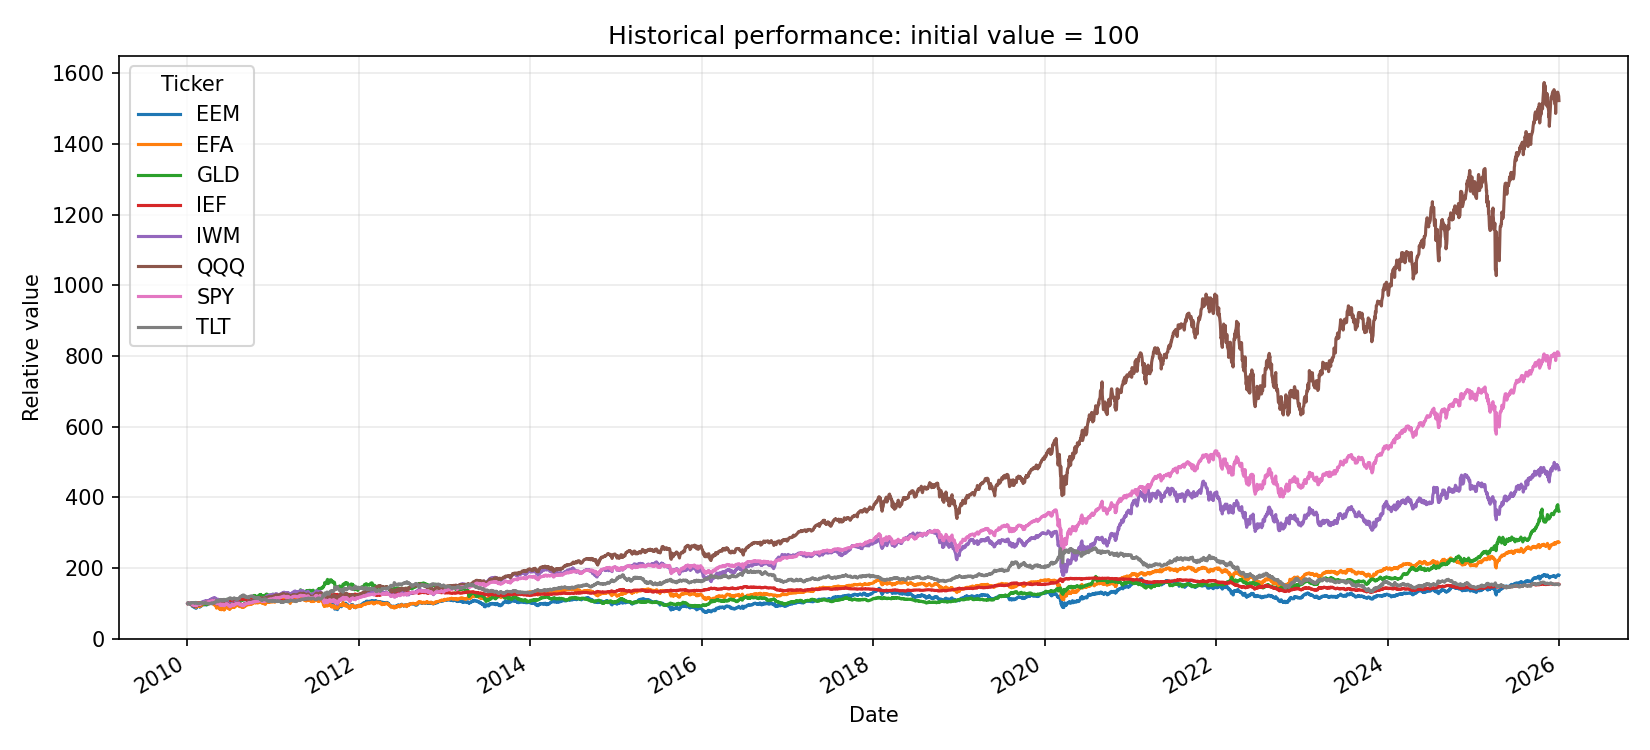

In [3]:
returns = (prices / prices.shift(1) - 1).iloc[1:]
print("Daily returns in percent:")
display((returns.head() * 100).round(2))
ax = (prices / prices.iloc[0] * 100).plot(figsize=(11, 5))
ax.set(title="Adjusted prices: initial value = 100", ylabel="Relative value")
ax.grid(alpha=0.25)
plt.show()
display(returns.corr().round(2))

## 5. Features and target

I use past returns over 1, 5, 20, and 60 sessions, 20-session volatility, and price relative to its 10-, 20-, and 60-session moving averages. I also include dummy variables for ticker, month, and weekday.

The target is 1 when the future return is positive and 0 otherwise. A signal is calculated at the close of t, entry is assumed at the close of t+1, and the return is measured through the close of t+2. This avoids assuming that a trade could be placed at a closing price after that price was already observed.

The first observations are lost because rolling features need history. The last two rows for each ETF have no observed future outcome and are kept for inference, not training.

In [4]:
data, features = etf_project.prepare_data(prices)
print("Number of predictive features:", len(features))
print("Features:", features)
display(data[["Date", "Ticker", "return_20", "volatility_20", "future_return", "target"]].head())
development = data[(data.Date < "2023-01-01") & (data.label_end < "2023-01-01")]
display(development.groupby("Ticker")["target"].agg(["count", "mean"]))
display(development[features + ["target"]].corr()["target"].drop("target").sort_values())

Number of predictive features: 33
Features: ['return_1', 'return_5', 'return_20', 'return_60', 'volatility_20', 'relative_sma_10', 'relative_sma_20', 'relative_sma_60', 'Ticker_EEM', 'Ticker_EFA', 'Ticker_GLD', 'Ticker_IEF', 'Ticker_IWM', 'Ticker_QQQ', 'Ticker_SPY', 'Ticker_TLT', 'Month_1', 'Month_10', 'Month_11', 'Month_12', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Weekday_0', 'Weekday_1', 'Weekday_2', 'Weekday_3', 'Weekday_4']


,Date,Ticker,return_20,volatility_20,future_return,target
60,2010-03-31,SPY,0.046142,0.004769,0.008150,1.0
61,2010-04-01,SPY,0.050116,0.004876,0.002358,1.0
62,2010-04-05,SPY,0.043755,0.004244,-0.005712,0.0
63,2010-04-06,SPY,0.046033,0.004218,0.003464,1.0
64,2010-04-07,SPY,0.038332,0.004580,0.006567,1.0


,count,mean
Ticker,,
EEM,3210,0.517757
EFA,3210,0.529595
GLD,3210,0.522741
IEF,3210,0.519938
IWM,3210,0.535202
QQQ,3210,0.553894
SPY,3210,0.547664
TLT,3210,0.524922


Weekday_3         -0.020240
Month_9           -0.017255
Weekday_1         -0.011762
return_5          -0.011429
Ticker_EEM        -0.010382
relative_sma_20   -0.009806
relative_sma_10   -0.009336
Month_10          -0.009202
Ticker_IEF        -0.008731
Month_11          -0.007406
Ticker_GLD        -0.006607
Month_5           -0.005577
Ticker_TLT        -0.004955
return_20         -0.003060
Ticker_EFA        -0.001416
Month_6           -0.000271
Month_8            0.000069
relative_sma_60    0.000908
volatility_20      0.001362
Month_3            0.002144
Ticker_IWM         0.002832
Month_4            0.002898
Month_1            0.006146
return_60          0.006404
return_1           0.007234
Month_12           0.007715
Weekday_0          0.008146
Weekday_4          0.009193
Month_7            0.010342
Month_2            0.011530
Ticker_SPY         0.012270
Weekday_2          0.014900
Ticker_QQQ         0.016989
Name: target, dtype: float64

## 6. Training and simulation

I compare a decision tree and a random forest. Training uses data before 2020, model selection uses 2020–2022 validation accuracy, and testing starts in 2023. Labels whose outcome dates cross a split boundary are excluded. After selecting the model, I refit it using development data available before 2023.

The simulation uses a fixed probability threshold of 0.55. Each ETF can occupy up to 1/8 of the capital. An allocation without a signal stays in cash with no interest. The benchmark keeps equal weights with daily rebalancing. Both include an approximate cost of 0.1% per side based on turnover.

Classification accuracy uses the model's predicted class; the trading simulation uses the 0.55 threshold. These evaluate different decisions. I did not optimize the threshold on the test set.

Rows per split: {'train': 19632, 'validation': 6032, 'test': 6000}
Validation:
Test:
Portfolios:
Top decision tree feature importances:


,model,accuracy,precision
0,decision_tree,0.512268,0.514626
1,random_forest,0.509781,0.513518


,model,accuracy,precision
0,decision_tree,0.5425,0.544414
1,always_up,0.5390,0.539000


,total_return,CAGR,annual_volatility,max_drawdown,sharpe_rf_0,total_turnover
model_strategy,0.0209,0.0070,0.0156,-0.0238,0.4532,31.8313
equal_weight_daily,0.5895,0.1685,0.1098,-0.1093,1.4732,5.0105


relative_sma_20    0.237009
return_1           0.229118
return_20          0.153682
return_60          0.139213
volatility_20      0.131914
return_5           0.071143
relative_sma_10    0.037922
relative_sma_60    0.000000
Ticker_EEM         0.000000
Ticker_EFA         0.000000
Ticker_GLD         0.000000
Ticker_IEF         0.000000
Ticker_IWM         0.000000
Ticker_QQQ         0.000000
Ticker_SPY         0.000000
dtype: float64

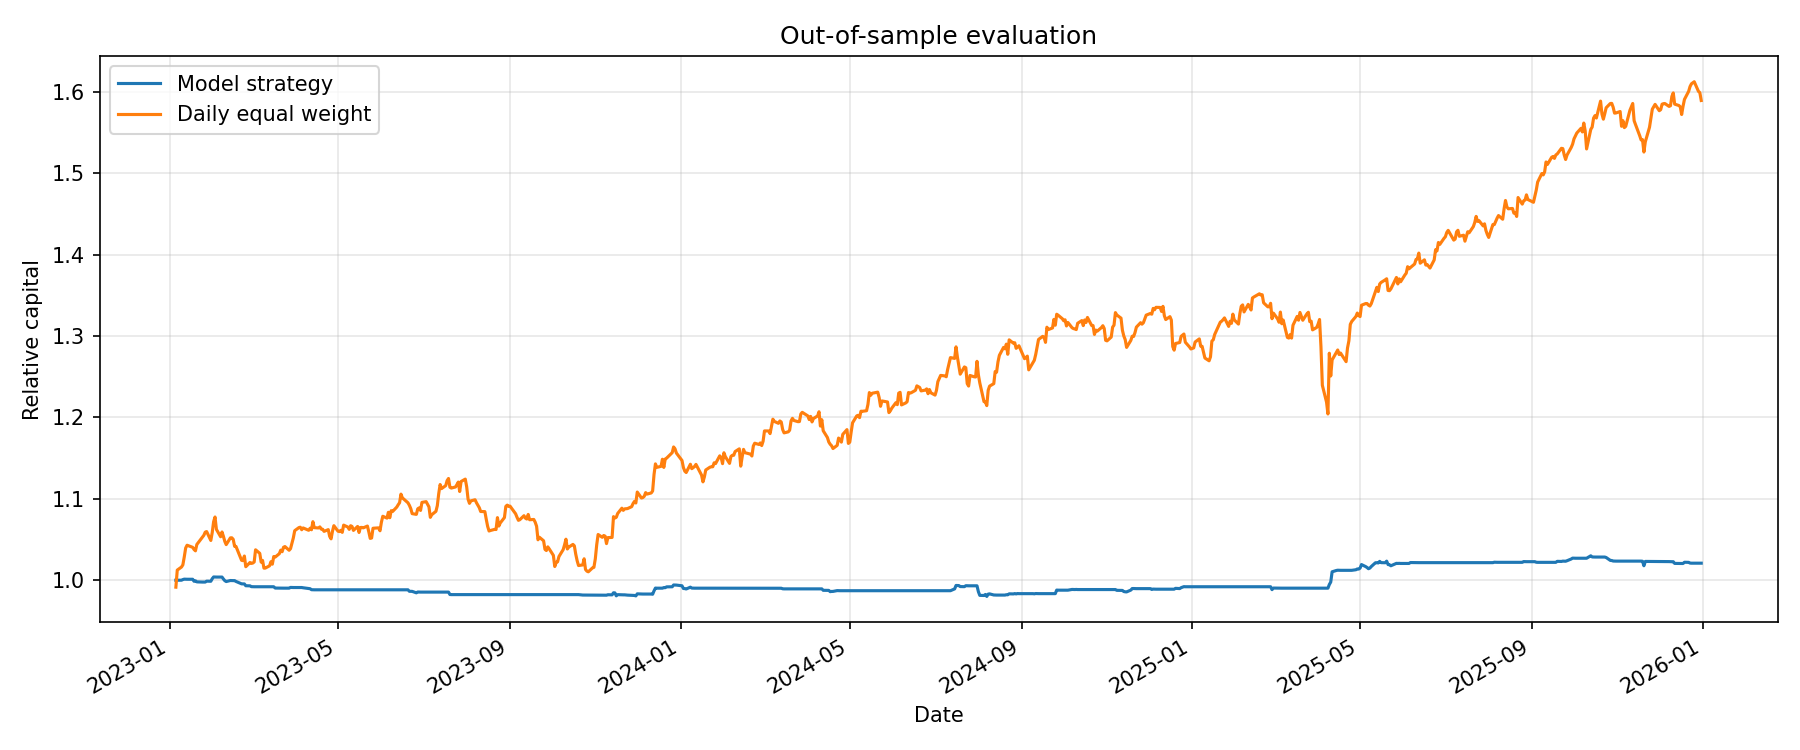

In [5]:
results = etf_project.run_project(prices)
print("Rows per split:", results["split_sizes"])
print("Validation:")
display(results["validation"])
print("Test:")
display(results["test"])
print("Portfolios:")
display(results["metrics"].round(4))
print("Top decision tree feature importances:")
display(results["importance"].head(15))

## 7. Drawdowns and independent trades

Drawdown measures how far capital falls below its previous peak. I also include a vectorized simulation following Module 4, using independent USD 100 trades and a 0.2% round-trip cost.

The sum of those independent trade profits is not a return on a portfolio with limited capital. For the portfolio comparison, I use the sequential simulation, which tracks available capital and reinvestment. There is no forced final liquidation; final holdings are marked to market.

Latest historical signals; model trained before 2023:


,selected_trades,gross_profit_usd,fees_usd,net_profit_usd
0,183,42.335113,36.6,5.735113


,Date,Ticker,probability_up,signal
4023,2025-12-31,SPY,0.540611,0
8047,2025-12-31,QQQ,0.540611,0
12071,2025-12-31,IWM,0.540611,0
16095,2025-12-31,EFA,0.540611,0
20119,2025-12-31,EEM,0.540611,0
24143,2025-12-31,TLT,0.540611,0
28167,2025-12-31,IEF,0.540611,0
32191,2025-12-31,GLD,0.632959,1


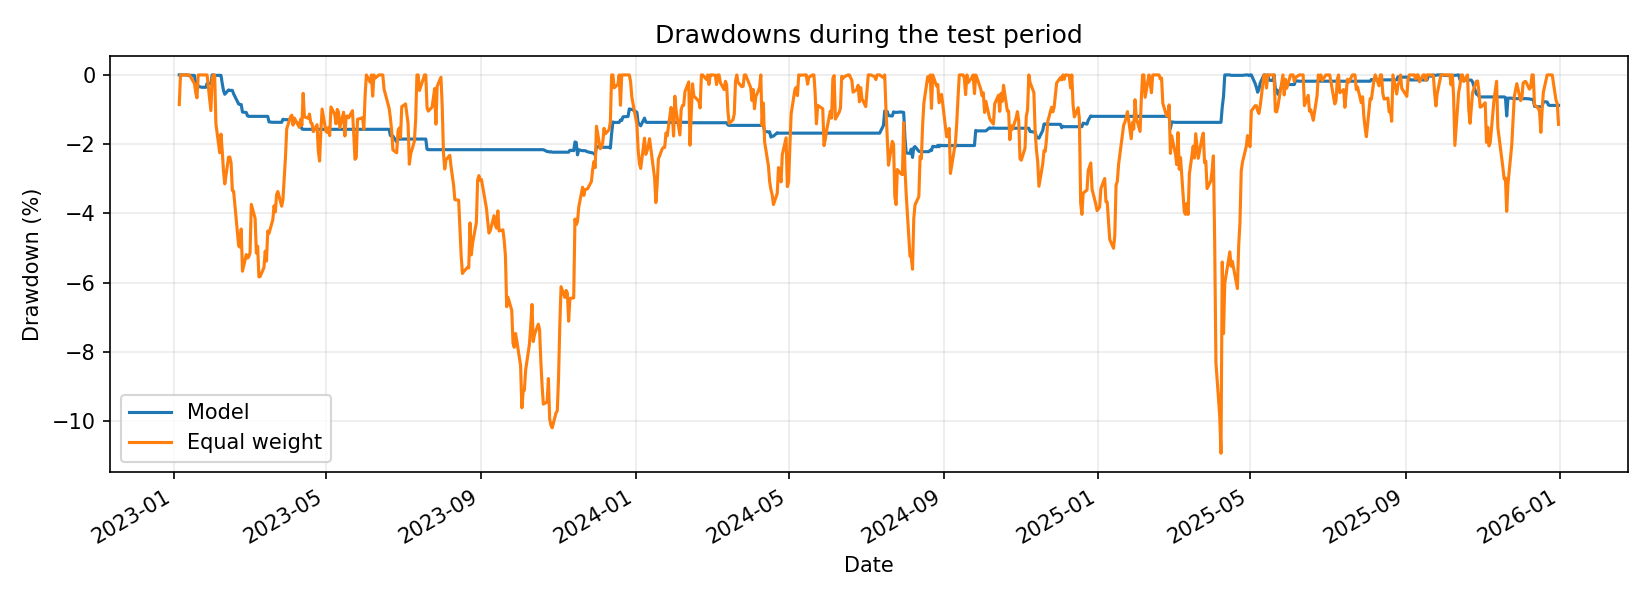

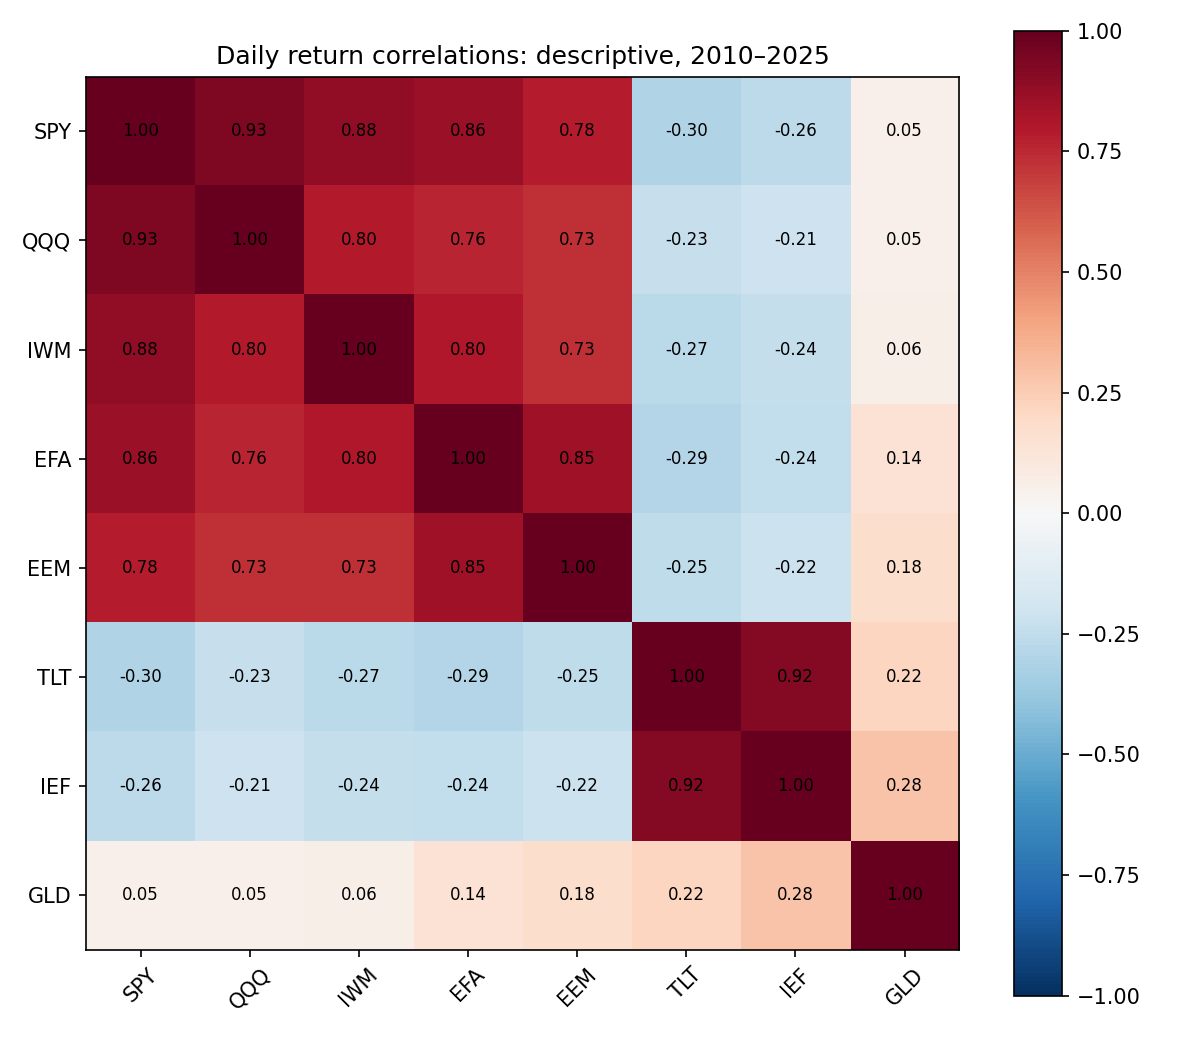

In [6]:
from IPython.display import Image, display
display(Image(filename="results/drawdown_comparison.png"))
display(Image(filename="results/correlations.png"))
display(pd.read_csv("results/independent_trade_summary.csv"))
print("Latest historical signals; model trained before 2023:")
display(results["latest"])

## 8. Running the project again

From a terminal, run `python etf_project.py`. The script downloads data and generates the results. This notebook runs the same analysis through `run_project`.

The CSV files and images in `results/` are analysis outputs, not the original price dataset. Prices are downloaded through the API rather than uploaded to the repository.

Yahoo may revise adjusted prices, and library versions can also affect results. A new run may therefore produce small differences. The environment versions and historical cutoff are recorded.

## What I found

The decision tree was selected on validation. Its test accuracy was 54.25%, compared with 53.90% for always predicting a positive return. That is a difference of 0.35 percentage points. The gap is small. I did not run a statistical significance test to establish whether it holds beyond this sample. Observations from different ETFs on the same date are also not independent.

| Metric | Model strategy | Daily equal weight |
|---|---:|---:|
| Total return | 2.09% | 58.95% |
| Compound annual growth rate | 0.70% | 16.85% |
| Annualized volatility | 1.56% | 10.98% |
| Maximum drawdown | -2.38% | -10.93% |
| Sharpe (risk-free rate = 0%) | 0.453 | 1.473 |


Selecting ETFs with the model did not improve returns in this simulation. The strategy gained 2.09%, while the equal-weight benchmark gained 58.95%. The strategy also had a lower Sharpe ratio.

Its maximum drawdown was smaller, but it also invested less capital because allocations stayed in cash when there was no signal. I cannot attribute the smaller drawdown only to better ETF selection. A comparison with similar invested exposure would help separate these effects.

What stood out to me was that getting slightly more predictions right did not lead to making more money. The size of each gain and loss, trading costs, and the amount of capital left in cash also matter.

I kept the parameters fixed after looking at test results. If I continue with other features or a different rebalancing frequency, I will need another evaluation period rather than choosing rules that fit these test results.
